# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [1]:
from __future__ import print_function
import os
data_path = ['data']

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

In [2]:
import pandas as pd

# в ячейке выше data_path = ['data'], но данные лежат в папке datasets
data_path = ['..', '..', '..', 'datasets']
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)

print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
# все признаки числовые, текстовая только колонка color
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

In [4]:
# white будет 0, red будет 1
data['color'] = data['color'].map({'white': 0, 'red': 1})
data['color'].value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

In [5]:
# признаки это все колонки, кроме color
feature_cols = [c for c in data.columns if c != 'color']

# по условию стратифицируем по quality, поэтому в split передаем data['quality'], а не color
# n_splits=1, то есть одно разбиение, test 30%. Индексы train_idx и test_idx пригодятся в вопросе 5
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
# split возвращает генератор, next берет из него первое (и единственное) разбиение
train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data['quality']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']
print(X_train.shape, X_test.shape)

(4547, 12) (1950, 12)


Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

In [6]:
# доля каждого уровня quality в train и test
quality_share = pd.concat([data.loc[train_idx, 'quality'].value_counts(normalize=True),
                           data.loc[test_idx, 'quality'].value_counts(normalize=True)], axis=1)
quality_share.columns = ['train', 'test']
quality_share.sort_index().round(4)

,train,test
quality,,
3,0.0046,0.0046
4,0.0332,0.0333
5,0.3290,0.3292
6,0.4366,0.4364
7,0.1660,0.1662
8,0.0297,0.0297
9,0.0009,0.0005


In [7]:
print('Train:')
print(y_train.value_counts(normalize=True).round(4))
print('Test:')
print(y_test.value_counts(normalize=True).round(4))

# доли quality в train и test почти одинаковые, это и дает стратификация
# в обоих наборах в основном белое вино (0.75 и 0.77). По color мы не стратифицировали, поэтому эти доли отличаются сильнее

Train:
color
0    0.7455
1    0.2545
Name: proportion, dtype: float64
Test:
color
0    0.7733
1    0.2267
Name: proportion, dtype: float64


## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

In [8]:
# дерево без ограничений: max_depth, max_features и max_leaf_nodes по умолчанию None
# random_state нужен, потому что при одинаково хороших разбиениях дерево выбирает случайно
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

Количество узлов и максимальная фактическая глубина.

In [9]:
print('узлов:', dt.tree_.node_count)
print('глубина:', dt.tree_.max_depth)

узлов: 143
глубина: 20


Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

In [10]:
# класс 1 это красное вино, precision, recall и f1 считаются для него
def measure_error(y_true, y_pred, label):
    return pd.Series({'accuracy': accuracy_score(y_true, y_pred),
                      'precision': precision_score(y_true, y_pred),
                      'recall': recall_score(y_true, y_pred),
                      'f1': f1_score(y_true, y_pred)},
                     name=label)

y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

full_error = pd.concat([measure_error(y_train, y_train_pred, 'train'),
                        measure_error(y_test, y_test_pred, 'test')], axis=1)
full_error.round(4)

,train,test
accuracy,0.9996,0.9862
precision,0.9991,0.9748
recall,0.9991,0.9638
f1,0.9991,0.9693


In [11]:
# дерево без ограничений, а accuracy на train не ровно 1. Посмотрим, на каких строках оно ошибается
wrong = X_train[y_train_pred != y_train]
print('ошибок на train:', len(wrong))

# все вина в данных с такими же признаками, как у этих строк
data.merge(wrong, on=feature_cols)

ошибок на train: 2


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,6.7,0.28,0.28,2.4,0.012,36.0,100.0,0.99064,3.26,0.39,11.7,7,1
1,6.7,0.28,0.28,2.4,0.012,36.0,100.0,0.99064,3.26,0.39,11.7,7,1
2,5.9,0.19,0.21,1.7,0.045,57.0,135.0,0.99341,3.32,0.44,9.5,5,1
3,6.7,0.28,0.28,2.4,0.012,36.0,100.0,0.99064,3.26,0.39,11.7,7,0
4,5.9,0.19,0.21,1.7,0.045,57.0,135.0,0.99341,3.32,0.44,9.5,5,0


Дерево без ограничений выросло до глубины 20 и 143 узлов и почти идеально запомнило train: accuracy 0.9996, а на test 0.9862. Сильнее всего на test падает recall для красного вина (с 0.9991 до 0.9638), то есть часть красных вин дерево принимает за белые. Значит, дерево переобучилось: оно подстроилось под отдельные вина из train, а на новых данных такие мелкие разбиения уже не помогают. Переобучение небольшое, потому что красное и белое вино по химическим свойствам и так хорошо различаются.

На train дерево ошибается всего на 2 винах. У них все признаки точно такие же, как у вина другого цвета (таблица выше), такие вина не разделит никакое разбиение, поэтому даже дерево без ограничений не получает на train ровно 1.

## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

In [12]:
# max_features это сколько случайных признаков дерево проверяет при выборе каждого разбиения
# глубину перебираем от 1 до глубины дерева из вопроса 3, признаков у нас 12
param_grid = {'max_depth': range(1, dt.tree_.max_depth + 1),
              'max_features': range(1, len(feature_cols) + 1)}

# по умолчанию cv=5 (для классификатора это StratifiedKFold) и scoring accuracy
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print('accuracy на кросс-валидации:', round(grid.best_score_, 4))

# после поиска GridSearchCV заново обучает лучшее дерево на всем train (refit=True по умолчанию)
# сохраняем его под другим именем, оно нужно в вопросе 6
dt_best = grid.best_estimator_

{'max_depth': 8, 'max_features': 7}
accuracy на кросс-валидации: 0.9839


Количество узлов и максимальная глубина дерева.

In [13]:
print('узлов:', dt_best.tree_.node_count)
print('глубина:', dt_best.tree_.max_depth)

узлов: 95
глубина: 8


Эти ошибки тестирования немного лучше, чем предыдущие. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

In [14]:
y_train_pred_best = dt_best.predict(X_train)
y_test_pred_best = dt_best.predict(X_test)

best_error = pd.concat([measure_error(y_train, y_train_pred_best, 'train'),
                        measure_error(y_test, y_test_pred_best, 'test')], axis=1)

# рядом ошибки дерева из вопроса 3
pd.concat([full_error, best_error], axis=1, keys=['full tree', 'grid search']).round(4)

# дерево после подбора мельче: глубина 8 вместо 20 и 95 узлов вместо 143. На train оно чуть хуже (accuracy 0.9956 против 0.9996),
# зато на test лучше по всем метрикам: accuracy 0.9903 против 0.9862, f1 0.9784 против 0.9693
# Разрыв между train и test стал меньше, значит, первое дерево действительно немного переобучалось

full tree         grid search        
              train    test       train    test
accuracy     0.9996  0.9862      0.9956  0.9903
precision    0.9991  0.9748      0.9982  0.9818
recall       0.9991  0.9638      0.9844  0.9751
f1           0.9991  0.9693      0.9913  0.9784

## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

In [15]:
# теперь цель residual_sugar, а color стал обычным признаком
feature_cols = [c for c in data.columns if c != 'residual_sugar']

# индексы из вопроса 2, поэтому в train и test те же строки, что и раньше
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'residual_sugar']
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'residual_sugar']

In [16]:
# сначала дерево без ограничений, только чтобы узнать глубину для сетки
dr = DecisionTreeRegressor(random_state=42)
dr.fit(X_train, y_train)
print('глубина дерева без ограничений:', dr.tree_.max_depth)

param_grid = {'max_depth': range(1, dr.tree_.max_depth + 1),
              'max_features': range(1, len(feature_cols) + 1)}

# по умолчанию у регрессии scoring R2, но ошибку мы оцениваем по MSE, поэтому и подбираем по ней.
# В sklearn это 'neg_mean_squared_error', со знаком минус, потому что GridSearchCV ищет максимум
grid_sugar = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid,
                          scoring='neg_mean_squared_error', n_jobs=-1)
grid_sugar.fit(X_train, y_train)

print(grid_sugar.best_params_)
print('MSE на кросс-валидации:', round(-grid_sugar.best_score_, 3))
dr_best = grid_sugar.best_estimator_

глубина дерева без ограничений: 29
{'max_depth': 15, 'max_features': 10}
MSE на кросс-валидации: 3.118


Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

In [17]:
print('узлов:', dr_best.tree_.node_count)
print('глубина:', dr_best.tree_.max_depth)

узлов: 4233
глубина: 15


Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

In [18]:
y_train_pred = dr_best.predict(X_train)
y_test_pred = dr_best.predict(X_test)

print('MSE train:', round(mean_squared_error(y_train, y_train_pred), 3))
print('MSE test:', round(mean_squared_error(y_test, y_test_pred), 3))
# для сравнения: если всегда предсказывать среднее, MSE будет примерно равна дисперсии
print('дисперсия residual_sugar на test:', round(y_test.var(), 3))

# на train MSE всего 0.081, а на test 2.857: дерево глубокое (15 уровней) и хорошо запоминает train
# Но по сравнению с дисперсией 21.447 ошибка на test маленькая, то есть дерево объясняет примерно 87% разброса сахара

MSE train: 0.081
MSE test: 2.857
дисперсия residual_sugar на test: 21.447


График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

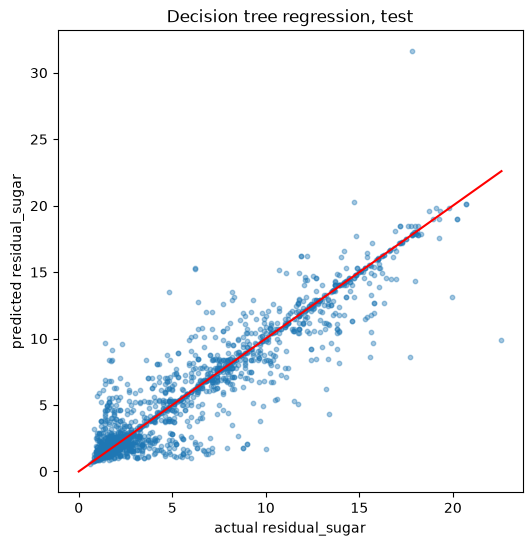

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_test_pred, s=10, alpha=0.4)
# на этой линии предсказание равно факту
ax.plot([0, y_test.max()], [0, y_test.max()], color='red')
ax.set(xlabel='actual residual_sugar', ylabel='predicted residual_sugar', title='Decision tree regression, test');

# большинство точек лежит около красной линии, но есть и сильные промахи: вино с сахаром около 18 дерево оценило
# больше чем в 30, а самое сладкое вино в test (около 23) примерно в 10

## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

In [20]:
try:
    import pydotplus
    pydotplus_installed = True
    
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

Дерево из вопроса 3.

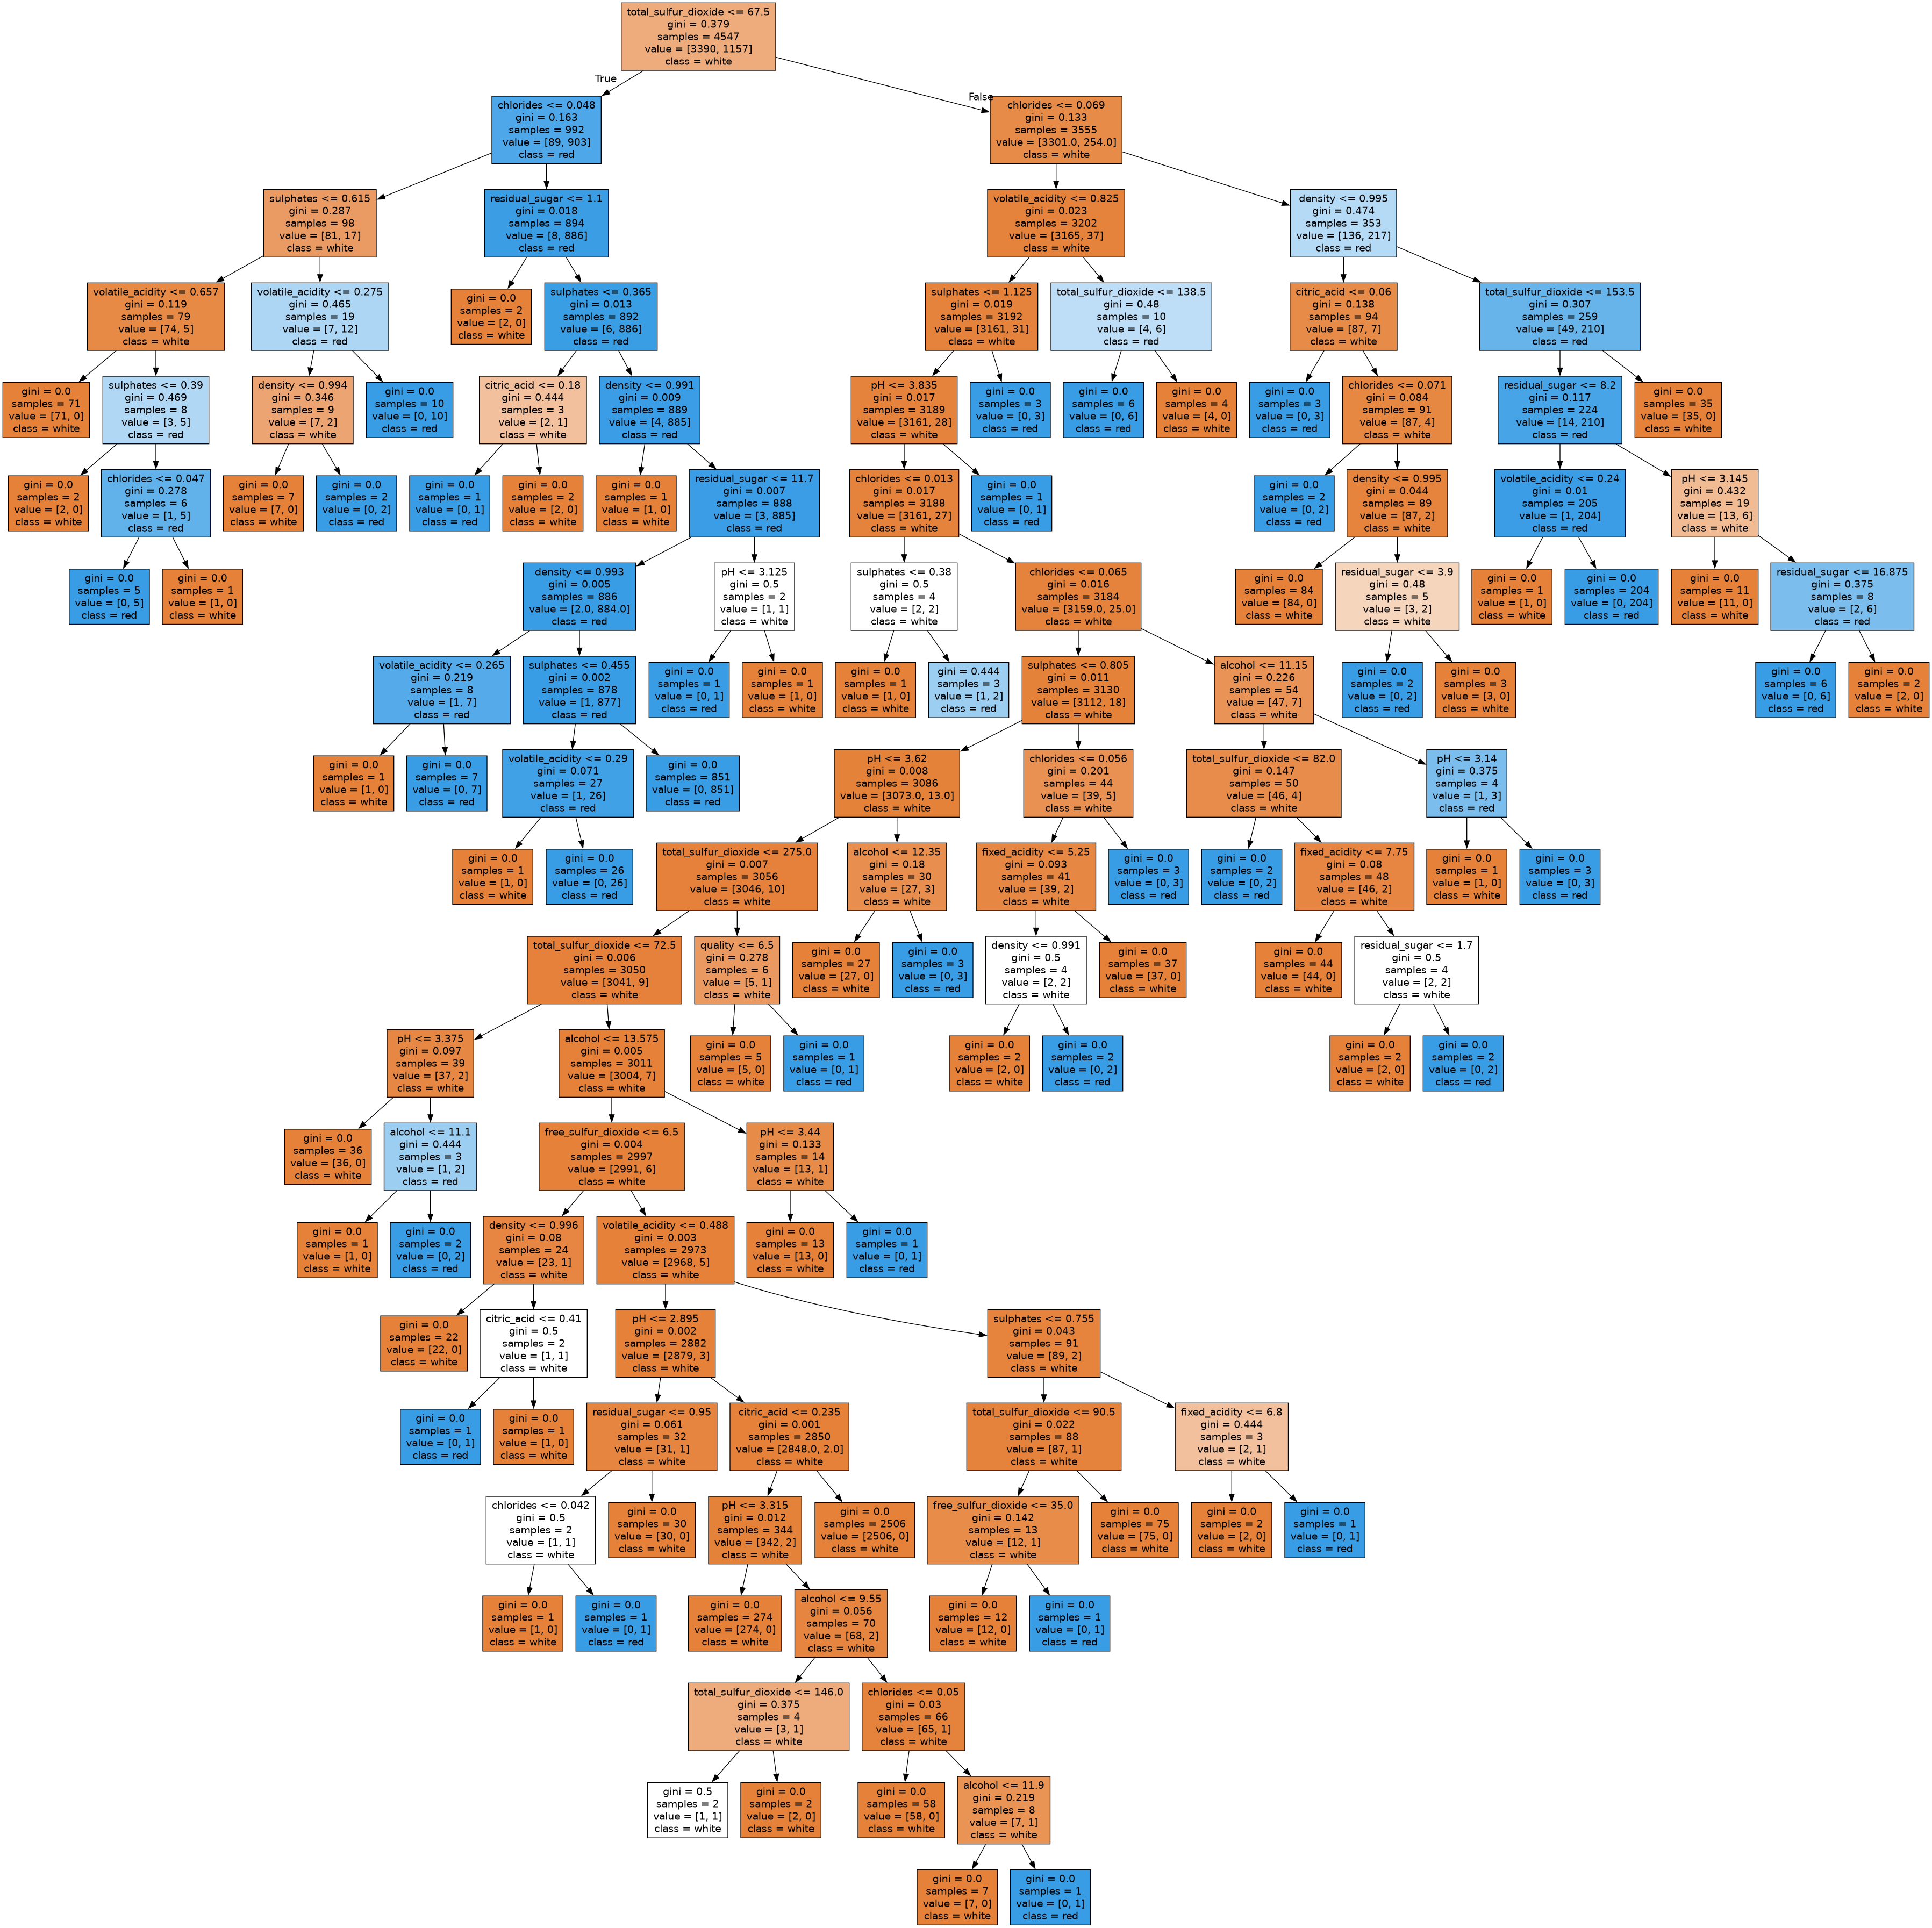

In [21]:
# export_graphviz записывает дерево в формате dot, а pydotplus рисует из него картинку через GraphViz
# feature_names_in_, потому что feature_cols в вопросе 5 уже поменялись
if pydotplus_installed:
    dot_data = StringIO()
    export_graphviz(dt, out_file=dot_data, filled=True,
                    feature_names=dt.feature_names_in_, class_names=['white', 'red'])
    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
    # pydotplus читает перенос строки в конце текста как лишний узел, на картинке это черный квадрат, поэтому удаляем его
    graph.del_node('"\\n"')
    display(Image(graph.create_png()))

Дерево, построенное с помощью перекрестной валидации из вопроса 4. Это дерево намного менее глубокое, чем предыдущее.

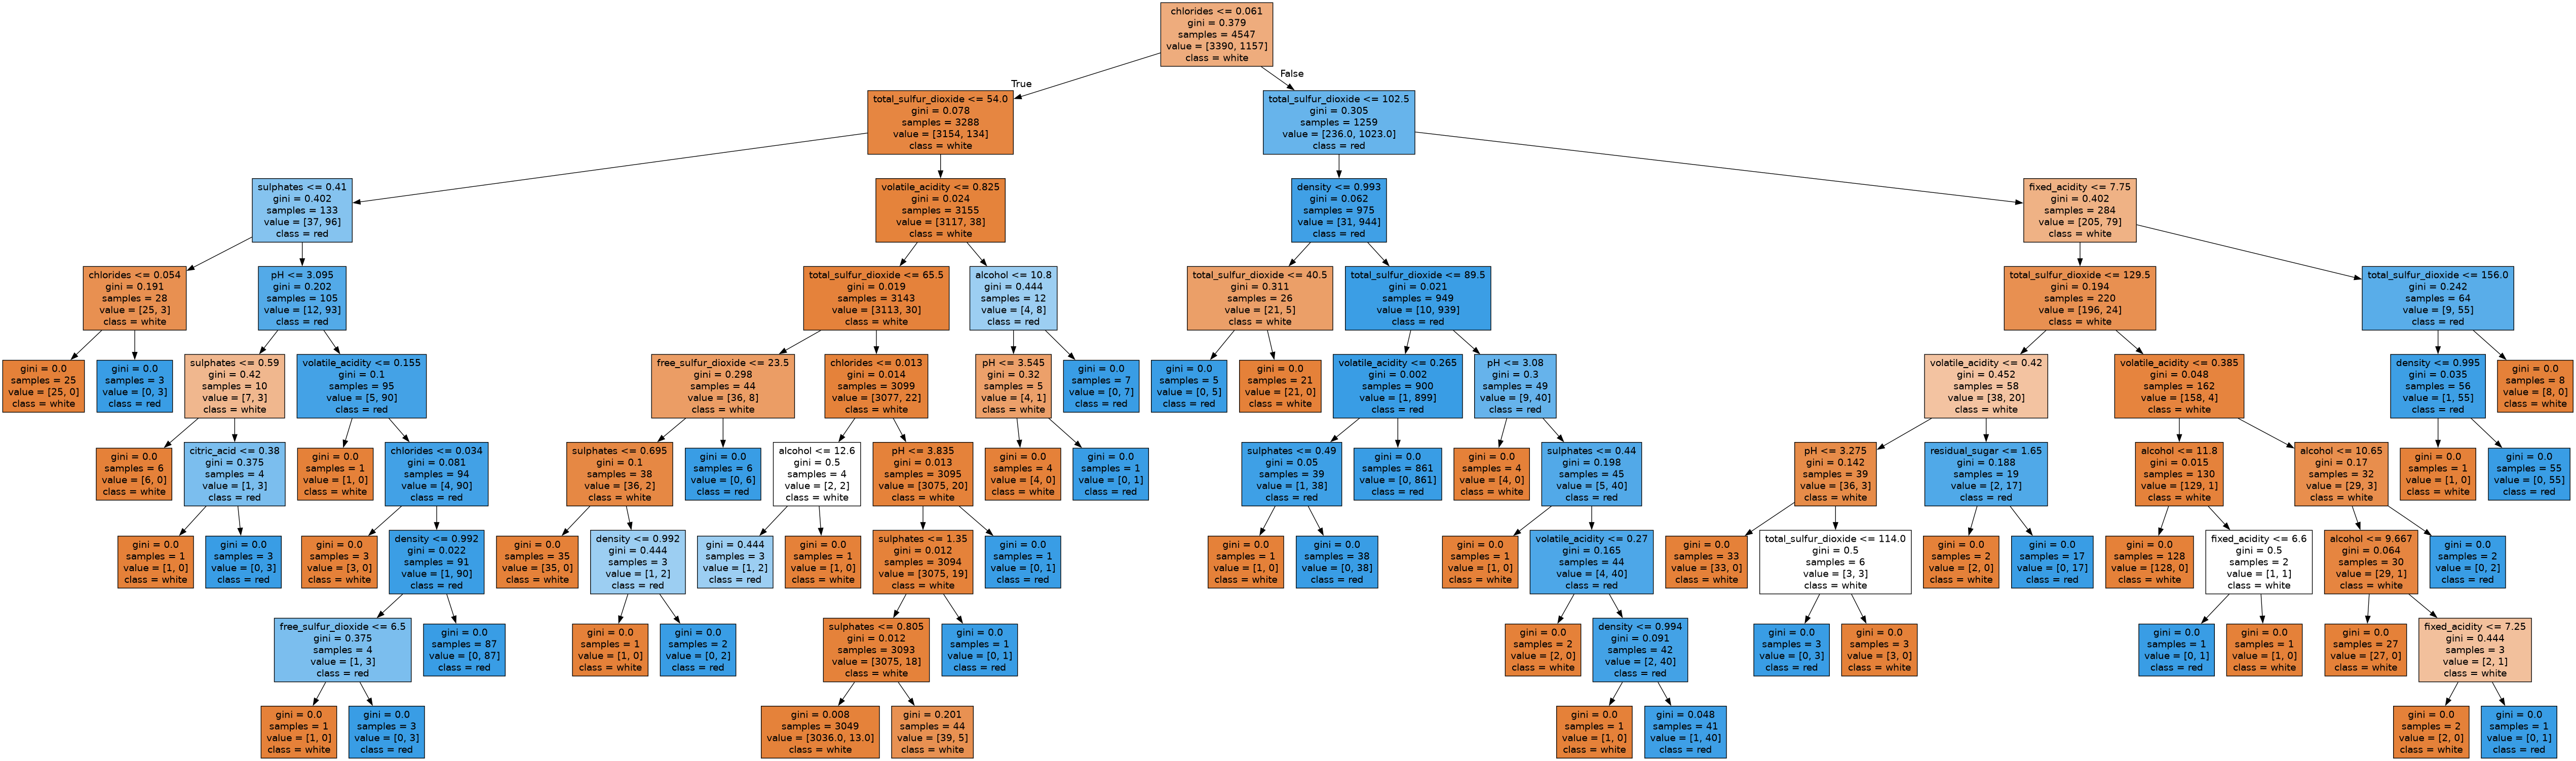

In [22]:
if pydotplus_installed:
    dot_data = StringIO()
    export_graphviz(dt_best, out_file=dot_data, filled=True,
                    feature_names=dt_best.feature_names_in_, class_names=['white', 'red'])
    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
    graph.del_node('"\\n"')
    display(Image(graph.create_png()))

# второе дерево мельче: глубина 8 вместо 20, но и в нем есть листья всего с одним-двумя винами.
# В корне у него chlorides, а не total_sulfur_dioxide, как у первого: с max_features=7 дерево в каждом узле
# выбирает только из 7 случайных признаков